# 04 · Reserving methods

**Question this notebook answers:** what does each standard method say, and, crucially, where does the BF prior come from?

| Method | Ultimate = | Relies on |
|---|---|---|
| **Chain ladder (CL)** | latest × CDF | the data only; highly leveraged when CDF is large |
| **Expected loss ratio (ELR)** | premium × prior LR | the prior only; ignores the data |
| **Bornhuetter-Ferguson (BF)** | latest + (1 − 1/CDF) × prior ultimate | data for what's emerged, prior for what hasn't |
| **Cape Cod** | BF, with the prior LR estimated *from the triangle itself* | the company's own experience, pooled across years |
| **Benktander** | BF repeated, using the BF ultimate as the new prior | credibility mix: weight on CL = % developed |

Each is run on both **paid** and **case incurred**. Every result is expressed as **unpaid = ultimate − paid to date** (case reserves + IBNR), the balance-sheet number, so paid- and incurred-based methods can be compared directly.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.factors import average_factors, cdfs
from reserving.methods import chain_ladder, bornhuetter_ferguson, cape_cod, cape_cod_elr, benktander
from reserving import backtest as B
from reserving.pipeline import company_prior, run_methods

df = D.load_cas()
co = D.company(df, cfg.STUDY_GRCODE)
universe = D.backtest_universe(df)
ind = D.industry(df, exclude=cfg.STUDY_GRCODE, grcodes=universe)
paid, case, prem = co.paid, co.case, co.premium
paid_latest = paid.latest_diagonal()
c_paid = cdfs(average_factors(paid), cfg.TAIL_PAID)
c_case = cdfs(average_factors(case), cfg.TAIL_CASE)

## 1. Chain ladder on paid and case incurred

In [3]:
cl_p, cl_c = chain_ladder(paid, c_paid), chain_ladder(case, c_case)
cl = pd.DataFrame({
    "premium": prem,
    "paid": paid_latest,
    "case incurred": case.latest_diagonal(),
    "paid CDF": cl_p["cdf"],
    "case CDF": cl_c["cdf"],
    "CL paid unpaid": cl_p["ultimate"] - paid_latest,
    "CL case unpaid": cl_c["ultimate"] - paid_latest,
    "CL paid LR": cl_p["ultimate"] / prem,
    "CL case LR": cl_c["ultimate"] / prem,
})
cl.loc["Total"] = cl.sum()
cl.loc["Total", ["paid CDF", "case CDF"]] = np.nan
cl.loc["Total", ["CL paid LR", "CL case LR"]] = [cl_p["ultimate"].sum() / prem.sum(), cl_c["ultimate"].sum() / prem.sum()]
cl.style.format({c: "{:,.0f}" for c in ["premium", "paid", "case incurred", "CL paid unpaid", "CL case unpaid"]}
                | {"paid CDF": "{:.3f}", "case CDF": "{:.3f}", "CL paid LR": "{:.1%}", "CL case LR": "{:.1%}"}, na_rep="")

,premium,paid,case incurred,paid CDF,case CDF,CL paid unpaid,CL case unpaid,CL paid LR,CL case LR
1988,"42,874","27,449","27,568",1.005,1.002,137,174,64.3%,64.4%
1989,"38,829","29,444","29,619",1.005,1.002,154,243,76.2%,76.5%
1990,"43,001","30,656","30,743",1.011,1.002,329,150,72.1%,71.6%
1991,"41,840","23,465","24,176",1.023,1.008,546,911,57.4%,58.3%
1992,"44,525","27,168","27,612",1.056,1.010,"1,526",724,64.4%,62.6%
1993,"50,923","33,803","35,987",1.102,1.014,"3,455","2,681",73.2%,71.6%
1994,"56,601","39,702","44,210",1.234,1.044,"9,287","6,442",86.6%,81.5%
1995,"54,609","32,406","40,550",1.515,1.107,"16,678","12,492",89.9%,82.2%
1996,"47,204","21,831","32,432",2.095,1.252,"23,895","18,781",96.9%,86.0%
1997,"42,412","9,076","19,392",4.755,1.842,"34,081","26,637",101.8%,84.2%


The two chain ladders agree on the mature years and diverge sharply on 1995-97. For 1997, CL paid implies a **~102% loss ratio** while CL case implies ~84%. The difference comes almost entirely from multiplying a small paid amount by a CDF of ~4.8.

## 2. The prior: where should BF's expected loss ratio come from?

In my first project the BF prior was the CL ultimate grown at an assumed 5%. That's circular: BF then inherits the very CL errors it's supposed to guard against. A proper prior must be **independent of the triangle's latest diagonal**. In practice it comes from the business plan / pricing loss ratio adjusted for rate changes and trend. Schedule P has no pricing data, so I build and compare three defensible alternatives:

| Prior | How | Strength | Weakness |
|---|---|---|---|
| **(a) Industry × relativity** | industry CL loss ratio by year × the company's relativity to industry on its mature years (1988-92) | external view, like a market benchmark | assumes the company moves with the market |
| **(b) Cape Cod** | one ELR = Σ reported / Σ "used-up" premium (premium ÷ CDF) | company's own data, objective, no judgement | one ELR for all years: misses any trend |
| **(c) Generalised Cape Cod** | as (b), but each year weights its neighbours by decay^distance (decay 0.75) | company's own data **and** allows a trend | more responsive, so a little more volatile |

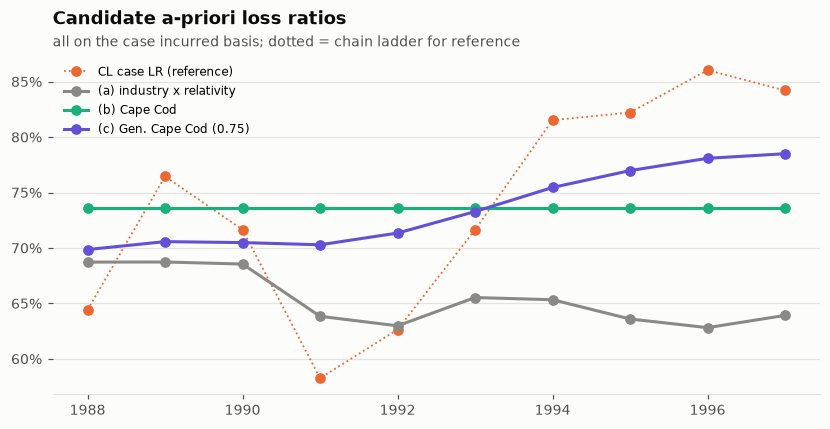

,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997
CL case LR (reference),64.4%,76.5%,71.6%,58.3%,62.6%,71.6%,81.5%,82.2%,86.0%,84.2%
(a) industry x relativity,68.7%,68.7%,68.6%,63.8%,63.0%,65.5%,65.3%,63.6%,62.8%,63.9%
(b) Cape Cod,73.6%,73.6%,73.6%,73.6%,73.6%,73.6%,73.6%,73.6%,73.6%,73.6%
(c) Gen. Cape Cod (0.75),69.9%,70.6%,70.5%,70.3%,71.3%,73.3%,75.5%,77.0%,78.1%,78.5%


In [4]:
prior_a = company_prior(co, ind, c_case)
elr_b = cape_cod_elr(case, c_case, prem)
elr_c = cape_cod_elr(case, c_case, prem, decay=cfg.CAPE_COD_DECAY)
priors = pd.DataFrame({
    "CL case LR (reference)": cl_c["ultimate"] / prem,
    "(a) industry x relativity": prior_a,
    "(b) Cape Cod": elr_b,
    "(c) Gen. Cape Cod (0.75)": elr_c,
})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(priors.index, priors.iloc[:, 0], color=PL.COLOURS["CL case"], marker="o", lw=1.2, ls=":", label=priors.columns[0])
ax.plot(priors.index, priors.iloc[:, 1], color=PL.NEUTRAL, marker="o", label=priors.columns[1])
ax.plot(priors.index, priors.iloc[:, 2], color=PL.COLOURS["Cape Cod case"], marker="o", label=priors.columns[2])
ax.plot(priors.index, priors.iloc[:, 3], color=PL.COLOURS["Gen. Cape Cod case"], marker="o", label=priors.columns[3])
ax.set_title("Candidate a-priori loss ratios")
PL.subtitle(ax, "all on the case incurred basis; dotted = chain ladder for reference")
PL.pct(ax)
ax.legend(fontsize=8, loc="upper left")
PL.save(fig, "04_priors")
plt.show()
priors.T.style.format("{:.1%}")

**Choosing the prior:**

* **(a) Industry × relativity** stays near 65% because the industry is flat. Notebook 02 showed the company has run well above the industry since 1994, so this prior would **understate** the recent years. That's exactly the years where BF leans on the prior most. I keep it as a sensitivity: it's what an actuary would get by trusting market benchmarks over the company's own experience.
* **(b) Cape Cod** gives a single ~74%. It's objective, but it assumes 1988 and 1997 share the same expected loss ratio, when the data shows a clear upward drift.
* **(c) Generalised Cape Cod** rises from ~70% to ~79%. It follows the drift, but because each year borrows from its neighbours it is far more stable than the CL loss ratios (it doesn't jump to 84-86% on the strength of thin recent data).

**Selected: (c) Generalised Cape Cod with decay 0.75.** The decay controls how fast the weight on neighbouring years falls off. Its sensitivity:

In [5]:
rows = {}
for d in [1.0, 0.9, 0.75, 0.5, 0.25]:
    r = cape_cod(case, c_case, prem, decay=d)
    rows[f"decay {d}"] = {"1997 ELR": r.loc[1997, "elr"], "total unpaid": (r["ultimate"] - paid_latest).sum()}
pd.DataFrame(rows).T.style.format({"1997 ELR": "{:.1%}", "total unpaid": "{:,.0f}"})

,1997 ELR,total unpaid
decay 1.0,73.6%,"65,462"
decay 0.9,75.4%,"66,056"
decay 0.75,78.5%,"67,042"
decay 0.5,82.7%,"68,423"
decay 0.25,84.3%,"69,085"


Decay 1.0 is the plain Cape Cod; as decay falls the estimate moves toward the chain ladder. 0.75 is a middle setting: the nearest year carries 75% of the weight of the year itself, two years away 56%, and so on. The result moves by only ~$2.4m between 0.9 and 0.5, so the choice isn't a hidden driver.

## 3. All methods side by side

In [6]:
results = run_methods(co, c_paid, c_case, prior_a)
ult = pd.DataFrame({k: v["ultimate"] for k, v in results.items()})
unpaid = ult.sub(paid_latest, axis=0)
show = unpaid.drop(columns="ELR")
tbl = show.copy()
tbl.loc["Total"] = tbl.sum()
tbl.style.format("{:,.0f}").background_gradient(axis=1, cmap="Blues", subset=pd.IndexSlice[tbl.index[:-1], :])

,CL paid,CL case,BF paid,BF case,Cape Cod paid,Cape Cod case,Gen. Cape Cod case,Benktander case
1988,137,174,147,178,160,182,179,174
1989,154,243,139,236,151,240,238,243
1990,329,150,313,148,342,152,149,150
1991,546,911,607,930,714,963,952,911
1992,"1,526",724,"1,492",726,"1,777",773,763,724
1993,"3,455","2,681","3,095","2,639","3,544","2,695","2,693","2,681"
1994,"9,287","6,442","7,010","6,058","8,052","6,253","6,298","6,436"
1995,"16,678","12,492","11,800","11,507","13,924","12,034","12,215","12,465"
1996,"23,895","18,781","15,495","16,573","18,511","17,595","18,025","18,629"
1997,"34,081","26,637","21,408","22,705","25,134","24,574","25,531","26,132"


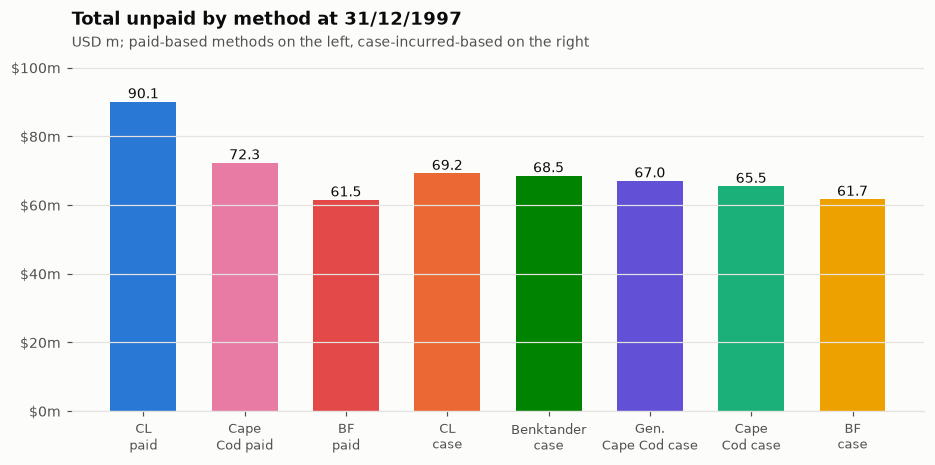

In [7]:
order = ["CL paid", "Cape Cod paid", "BF paid", "CL case", "Benktander case", "Gen. Cape Cod case", "Cape Cod case", "BF case"]
fig, ax = plt.subplots(figsize=(10, 4.2))
tot = show[order].sum() / 1e3
cols = [PL.COLOURS[m] for m in order]
ax.bar(range(len(order)), tot.values, color=cols, width=0.65)
for i, v in enumerate(tot.values):
    ax.text(i, v + 1, f"{v:,.1f}", ha="center", fontsize=9, color=PL.INK)
ax.set_xticks(range(len(order)), [o.replace(" ", "\n", 1) for o in order], fontsize=8.5)
ax.set_title("Total unpaid by method at 31/12/1997")
PL.subtitle(ax, "USD m; paid-based methods on the left, case-incurred-based on the right")
PL.money(ax, unit="m", prefix="$")
ax.set_ylim(0, tot.max() * 1.15)
PL.save(fig, "04_total_by_method")
plt.show()

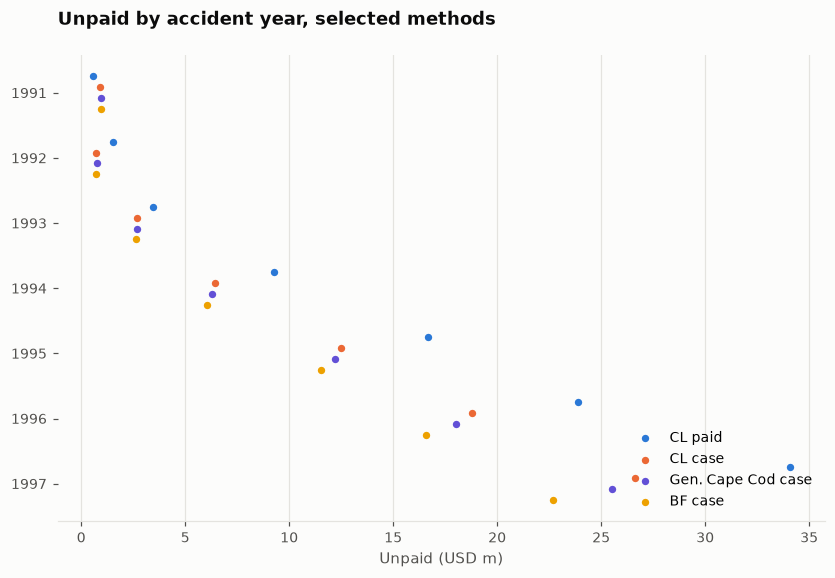

In [8]:
ax = PL.method_dots(show[["CL paid", "CL case", "Gen. Cape Cod case", "BF case"]].loc[1991:], title="Unpaid by accident year, selected methods", scale=1e3, unit="USD m")
PL.save(ax.figure, "04_unpaid_by_ay")
plt.show()

**What the comparison shows:**

* The **paid chain ladder is the outlier** at ~$90m. Every other method lies between $61m and $72m.
* Among case-based methods the spread is narrower ($62-69m). The difference between them is almost entirely **the prior**: BF with the industry prior is lowest, because that prior is low; the Gen. Cape Cod and Benktander results sit close to CL case.
* For mature years (1988-92) all methods agree within a few hundred thousand dollars. The judgement is concentrated in **1994-97**.

## 4. Why not just use the chain ladder? Leverage

A simple test: suppose 1997's paid to date had come in **10% higher** purely by chance (one large early settlement). How much does each method's 1997 ultimate move?

In [9]:
from reserving.triangle import Triangle
bump = paid.values.copy()
bump.loc[1997, 1] *= 1.10
paid_b = Triangle(bump)
base = {
    "CL paid": chain_ladder(paid, c_paid).loc[1997, "ultimate"],
    "BF paid (Gen. CC prior)": bornhuetter_ferguson(paid, c_paid, prem * elr_c).loc[1997, "ultimate"],
}
shock = {
    "CL paid": chain_ladder(paid_b, c_paid).loc[1997, "ultimate"],
    "BF paid (Gen. CC prior)": bornhuetter_ferguson(paid_b, c_paid, prem * elr_c).loc[1997, "ultimate"],
}
lev = pd.DataFrame({"base ultimate": base, "after +10% paid": shock})
lev["change"] = lev["after +10% paid"] - lev["base ultimate"]
lev["change as % of the paid shock"] = lev["change"] / (paid.values.loc[1997, 1] * 0.10)
lev.style.format({"base ultimate": "{:,.0f}", "after +10% paid": "{:,.0f}", "change": "{:,.0f}", "change as % of the paid shock": "{:.0%}"})

,base ultimate,after +10% paid,change,change as % of the paid shock
CL paid,"43,157","47,473","4,316",476%
BF paid (Gen. CC prior),"35,368","36,276",908,100%


The chain ladder turns a $0.9m random payment into a **$4.3m** change in ultimate (×4.8). BF passes through exactly the $0.9m that was actually paid, and nothing more. For immature years, where a single claim can move the latest diagonal, that stability is why BF-type methods are preferred. The price is that BF is only as good as its prior, which is why section 2 matters.

## Conclusions → next steps

* Methods range from **$61m to $90m** total unpaid. Paid CL is the clear high outlier; case-based methods cluster at $62-69m.
* **Prior:** Generalised Cape Cod on case incurred (company's own data, allows the upward loss-ratio trend). The industry-based prior is kept as a sensitivity and is the lowest result.
* The key unresolved question is still **paid vs case** for 1994-97. Notebook 05 quantifies statistical uncertainty, notebook 06 asks which methods have historically been right at each maturity, and notebook 08 makes the selection.